# Lab 2 · Phân loại cảnh quan theo pipeline 16 bước

Báo cáo dùng kết quả WF-LAB2-001 trên Intel Image Classification. Chạy từ đầu với kernel Lab2 (.venv) để xem số liệu và thử một ảnh ở mục 16. [Quy trình chạy năm phase](main.ipynb) · [Description](../docs/labs2-description.md)

## 01. DEFINE PROBLEM · Xác định bài toán

Đầu vào là ảnh RGB. Đầu ra là một nhãn trong sáu lớp buildings, forest, glacier, mountain, sea và street. Ta so sánh VGG11 với DenseNet121 trên cùng tập validation, đồng thời đo phần cải thiện khi mở khối cuối để fine-tune. Checkpoint thắng được đánh giá trên test bằng accuracy, macro-F1 và cross-entropy.

In [1]:
from pathlib import Path
import csv, sys
from IPython.display import display, Markdown, Image
root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.common import ROOT, read_json, sha256
out = ROOT / 'outputs'
runs = out / 'training-scene-v1'
evaluation = out / 'evaluation-scene-v1'
selection = read_json(runs / 'report.json')
assert selection['manifest'] == sha256(out / 'data/manifest.csv') and not selection['smoke']

## 02. DATA SPLIT · Chia tập

Train và validation được chia phân tầng gần tỷ lệ 80/20 với seed 42 và ràng buộc giữ cùng nhóm cảnh. Tập test gốc giữ đủ 3.000 ảnh. Phép kiểm dưới đối chiếu khóa nội dung RGB và mã nhóm giữa từng cặp tập.

In [2]:
from itertools import combinations
splits = ('train', 'validation', 'test')
with (out / 'data/manifest.csv').open(encoding='utf-8-sig') as f:
    manifest = list(csv.DictReader(f))
for key in ('sha256', 'group_id'):
    sets = {s: {r[key] for r in manifest if r['split'] == s} for s in splits}
    for left, right in combinations(splits, 2):
        common = sets[left] & sets[right]
        assert not common, (left, right, key)
    print(key, '· không giao nhau giữa train, validation và test')

sha256 · không giao nhau giữa train, validation và test
group_id · không giao nhau giữa train, validation và test


## 03. EDA · Khám phá dữ liệu

Bộ Intel có 14.034 ảnh development có nhãn, 3.000 ảnh test và 7.301 ảnh demo chưa gán nhãn. Bảng dưới cho phân bố từng lớp sau rà soát. Mountain có nhiều ảnh train nhất, forest có ít ảnh test hơn glacier. Vì số ảnh mỗi lớp khác nhau, ta xem thêm recall từng lớp. [Nguồn Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification/data) · [Khảo sát kích thước, màu và ảnh mẫu](eda.ipynb)

In [3]:
audit = read_json(out / 'data/audit.json')
counts = audit['counts']
rows = [(c, *(counts[s][c] for s in splits)) for c in audit['classes']]
rows.append(('Tổng', *(sum(counts[s].values()) for s in splits)))
def table(headers, rows):
    lines = [headers, ['---'] * len(headers), *rows]
    display(Markdown('\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in lines)))
table(['Lớp', *splits], rows)

| Lớp | train | validation | test |
| --- | --- | --- | --- |
| buildings | 1749 | 437 | 437 |
| forest | 1809 | 452 | 474 |
| glacier | 1914 | 479 | 553 |
| mountain | 2002 | 500 | 525 |
| sea | 1799 | 450 | 510 |
| street | 1900 | 475 | 501 |
| Tổng | 11173 | 2793 | 3000 |

## 04. CLEANING · Xử lý ảnh trùng và nhóm chưa chắc

Rà 356 cặp gần trùng xác định 62 cặp cùng cảnh, 265 cặp khác cảnh và 29 cặp chưa chắc. Quy tắc xử lý loại 68 ảnh development khỏi manifest, gồm 28 ảnh do trùng tuyệt đối hoặc xung đột nhãn, 18 ảnh thuộc nhóm chạm test và 22 ảnh thuộc nhóm chưa chắc. Số cặp và số ảnh là hai đơn vị khác nhau. [Quyết định từng nhóm](../outputs/scene-review/report.md)

In [4]:
from collections import Counter
with (out / 'data/excluded.csv').open(encoding='utf-8-sig') as f:
    removed = Counter(r['reason'] for r in csv.DictReader(f))
assert sum(removed.values()) + sum(counts['train'].values()) + sum(counts['validation'].values()) == 14034
table(['Lý do ghi trong audit', 'Số ảnh'], removed.items())

| Lý do ghi trong audit | Số ảnh |
| --- | --- |
| conflicting_labels | 23 |
| duplicate_or_test_overlap | 5 |
| scene_touches_test | 18 |
| unresolved_pair | 22 |

## 05. FEATURE ENGINEERING · Tiền xử lý và đặc trưng

Ảnh train được resize, crop ngẫu nhiên thành 224×224 và lật ngang để mô hình gặp nhiều biến thể của cùng cảnh. Validation, test và demo dùng center crop xác định và cùng chuẩn hóa ImageNet. Backbone pretrained biến tensor ảnh thành đặc trưng để lớp Linear học cách phân biệt sáu lớp. [Mã tiền xử lý](../src/phases/phase_02_data.py)

## 06. BASELINE MODEL · Hai mốc so sánh

Baseline thứ nhất luôn đoán lớp đông nhất trên train. Baseline thứ hai lấy checkpoint tốt nhất khi chỉ học classifier. Mốc thứ hai giúp đo lợi ích của fine-tuning trên cùng split.

In [5]:
majority = max(counts['train'], key=counts['train'].get)
print(f"Đoán {majority}: {counts['validation'][majority]}/{sum(counts['validation'].values())} ảnh đúng")
for name in ('vgg11','densenet121'):
    history = read_json(runs / name / 'history.json')
    head = min((r for r in history if r['stage']=='transfer'), key=lambda r: (-r['val_accuracy'],r['val_loss'],r['epoch']))
    print(f"{name}: epoch {head['epoch']}, val accuracy {head['val_accuracy']:.2%}")

Đoán mountain: 500/2793 ảnh đúng
vgg11: epoch 4, val accuracy 92.37%
densenet121: epoch 4, val accuracy 92.37%


## 07. MODEL SELECTION · Chọn kiến trúc ứng viên

VGG11 qua 5 khối convolution và classifier. DenseNet121 qua 4 dense block và global average pooling. Cả hai thay lớp Linear cuối bằng lớp có 6 đầu ra. Giai đoạn đầu chỉ học Linear mới. Khi fine-tune, VGG11 mở thêm hai convolution cuối, DenseNet121 mở denseblock4 và norm5. [Số tham số và kiểm tra freeze](../docs/model.md)

## 08. HYPERPARAMETER TUNING · Khảo sát learning rate

Hai run chính dùng LR 0,0003 khi học classifier và 0,00001 khi fine-tune. Nhánh VGG11 phụ bắt đầu từ cùng checkpoint chuyển tiếp và dùng LR 0,000003. Nhánh LR thấp đạt 92,98% validation accuracy, so với 93,48% của VGG11 chính. Kết luận chỉ áp dụng cho cặp LR này trên bản chia hiện tại.

## 09. TRAIN MODEL · Huấn luyện và chọn checkpoint

Mỗi run chính dùng Adam, cross-entropy và batch 8. Sau 5 epoch học classifier, model nạp best của stage đầu và fine-tune tối đa 15 epoch. Dừng khi validation loss chưa cải thiện đủ 0,0001 trong 3 epoch liên tiếp. Checkpoint ưu tiên số đúng validation, sau đó loss thấp hơn rồi epoch sớm hơn. Nhánh LR phụ chỉ tính epoch fine-tuning.

| Run | Epoch đã chạy | Best epoch | Val accuracy | Val loss |
| --- | --- | --- | --- | --- |
| vgg11 | 10 | 7 | 93.48% | 0.2016 |
| densenet121 | 12 | 9 | 93.56% | 0.1878 |
| vgg11-lr-ablation | 5 | 9 | 92.98% | 0.2104 |

**vgg11**

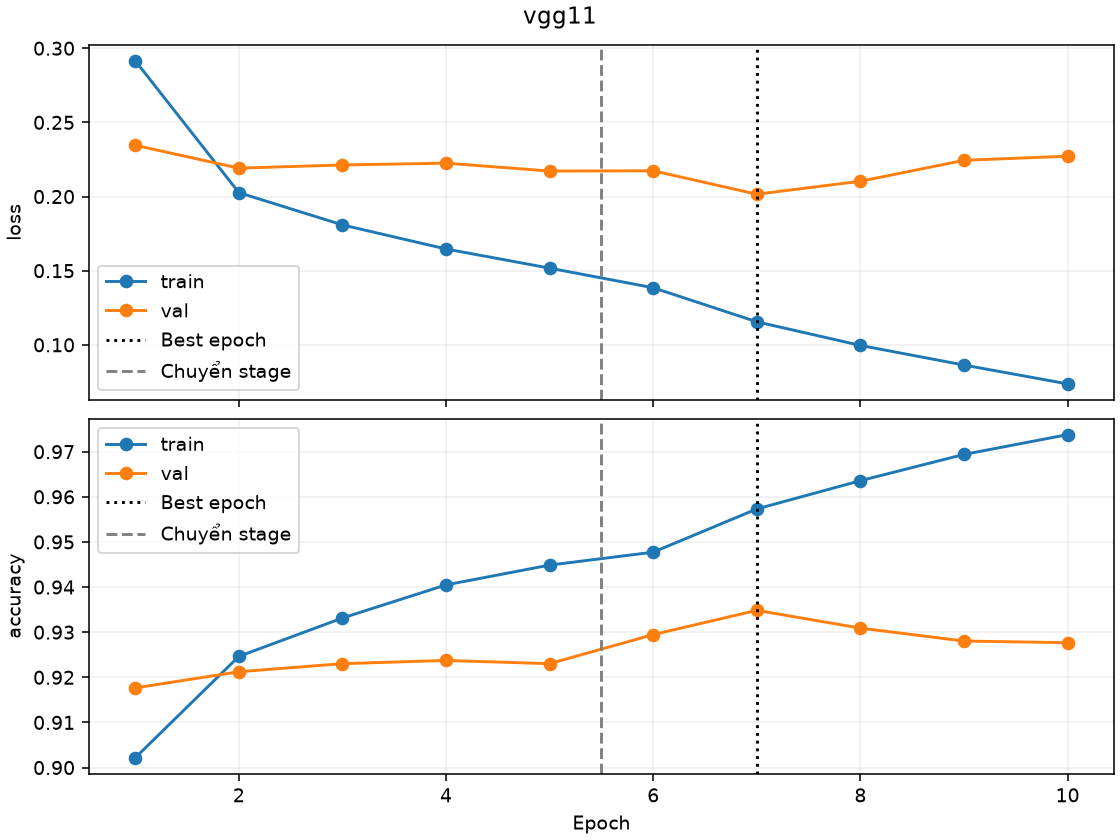

**densenet121**

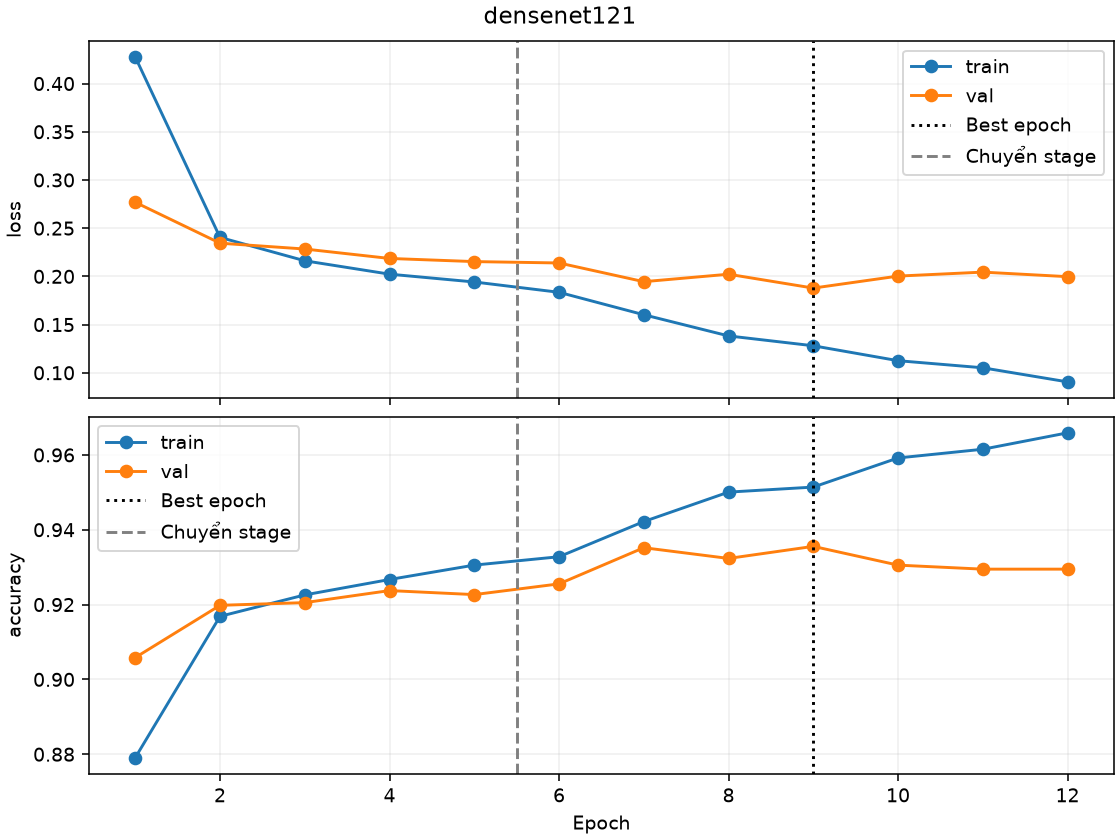

**vgg11-lr-ablation**

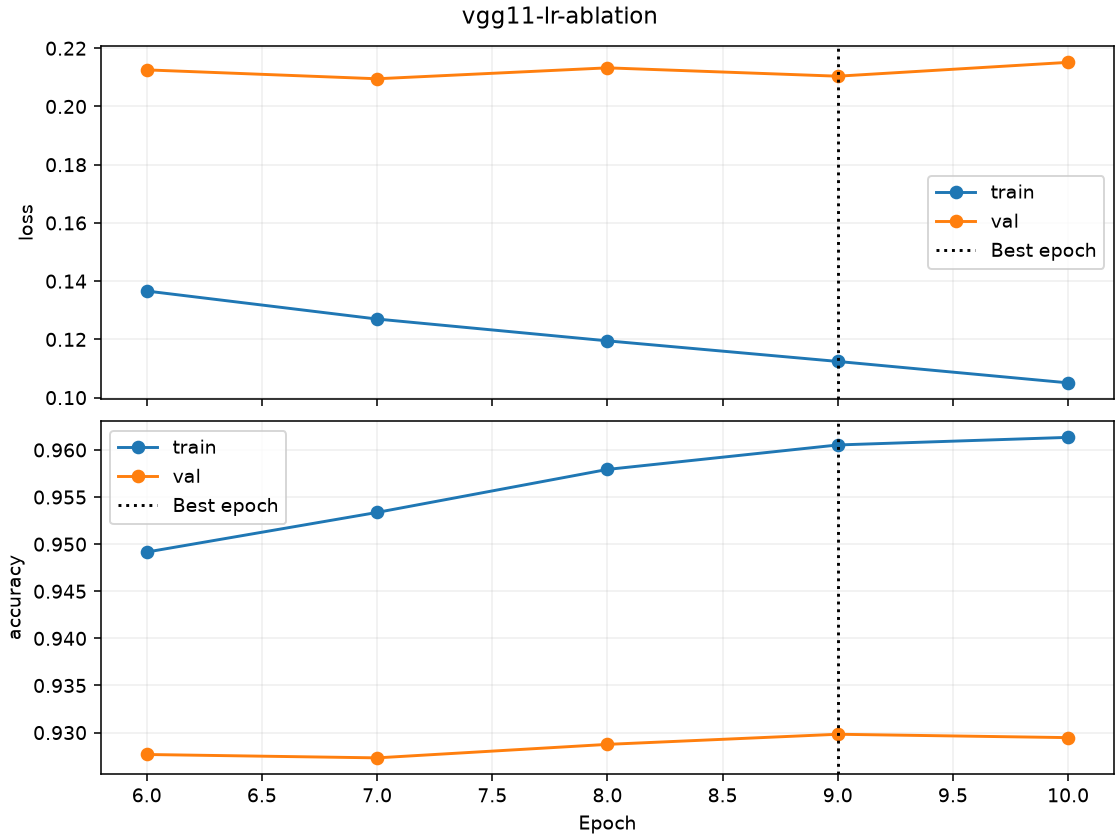

In [6]:
summary = []
for name in selection['runs']:
    run = read_json(runs / name / 'result.json')
    best = run['best']
    summary.append((name, len(run['history']), best['epoch'], f"{best['val_accuracy']:.2%}", f"{best['val_loss']:.4f}"))
table(['Run', 'Epoch đã chạy', 'Best epoch', 'Val accuracy', 'Val loss'], summary)
for name in selection['runs']:
    display(Markdown('**' + name + '**'))
    display(Image(filename=str(runs / name / 'curves.png')))

VGG11 đúng 2.611 ảnh validation; DenseNet121 đúng 2.613 trên cùng 2.793 ảnh. Quy tắc đã đặt chọn DenseNet121 epoch 9. Sau epoch 9, train loss tiếp tục giảm nhưng validation loss không cải thiện qua ba epoch; VGG11 có diễn biến tương tự sau epoch 7. Khoảng cách này là dấu hiệu overfitting và giải thích vì sao dùng checkpoint tốt nhất thay cho epoch cuối.

## 10. EVALUATION METRICS · Đánh giá checkpoint đã khóa

Nạp DenseNet121 epoch 9 đã chọn bằng validation. Precision cho biết trong các ảnh dự đoán là một lớp thì bao nhiêu đúng. Recall cho biết trong các ảnh thật của lớp đó thì bao nhiêu được nhận ra. Macro-F1 lấy trung bình F1 của sáu lớp.

In [7]:
m = read_json(evaluation / 'metrics.json')
cm = m['confusion_matrix']
assert selection['selected_by_validation'] == m['version']['model']
assert sha256(runs / m['version']['model'] / 'best.pt') == m['version']['checkpoint_sha256']
correct = sum(row[i] for i, row in enumerate(cm))
assert sum(map(sum, cm)) == m['samples'] and correct / m['samples'] == m['accuracy']
print(f"Đúng {correct}/{m['samples']} | accuracy {m['accuracy']:.2%} | macro-F1 {m['macro_f1']:.4f} | loss {m['loss']:.4f}")
with (evaluation / 'per-class.csv').open(encoding='utf-8-sig') as f:
    table(['Lớp', 'Precision', 'Recall', 'F1', 'Số ảnh'], [(r['name'], *(f"{float(r[k]):.2%}" for k in ('precision','recall','f1')), r['support']) for r in csv.DictReader(f)])

Đúng 2793/3000 | accuracy 93.10% | macro-F1 0.9326 | loss 0.1870


| Lớp | Precision | Recall | F1 | Số ảnh |
| --- | --- | --- | --- | --- |
| buildings | 93.18% | 93.82% | 93.50% | 437 |
| forest | 98.75% | 99.79% | 99.27% | 474 |
| glacier | 91.05% | 84.63% | 87.72% | 553 |
| mountain | 86.03% | 90.29% | 88.10% | 525 |
| sea | 95.59% | 97.84% | 96.71% | 510 |
| street | 94.94% | 93.61% | 94.27% | 501 |

## 11. CROSS VALIDATION · Phạm vi kiểm chứng

Thực nghiệm sử dụng một bản chia cố định theo nhóm cảnh và seed 42. Chưa chạy k-fold trên manifest này. Vì vậy, các giá trị được báo cáo là kết quả của một split. Nếu thiết kế cross-validation sau này, mỗi nhóm cảnh cần thuộc trọn một fold để tránh rò rỉ.

## 12. EXPERIMENT MANAGEMENT · Quản lý thí nghiệm

Mỗi run lưu history.json, run.log, các sự kiện TensorBoard và checkpoint riêng. best.pt dùng cho đánh giá và demo, last.pt dùng để tiếp tục training. Dòng dưới giúp tìm log theo run. [Smoke và cách mở TensorBoard](../docs/training.md)

In [8]:
for name in selection['runs']:
    folder = runs / name
    assert (folder / 'run.log').is_file() and any((folder / 'tensorboard').rglob('events.out.tfevents.*'))
    print((folder / 'run.log').relative_to(ROOT))

outputs\training-scene-v1\vgg11\run.log
outputs\training-scene-v1\densenet121\run.log
outputs\training-scene-v1\vgg11-lr-ablation\run.log


## 13. STATISTICAL VALIDATION · Giới hạn của phép so sánh

Trên cùng 2.793 ảnh validation, DenseNet121 đúng 2.613 và VGG11 đúng 2.611. Chênh lệch quan sát là 2 ảnh, khoảng 0,072 điểm phần trăm. Hai tổng số đúng chưa cho biết hai model sai trên những ảnh nào. Thực nghiệm chưa chạy kiểm định theo cặp hoặc lặp nhiều seed. Tập test từng được xem trong phiên bản Lab trước.

## 14. ERROR ANALYSIS · Phân tích lỗi

Đọc ma trận theo hàng là nhãn thật, theo cột là dự đoán. Trong 207 ảnh sai, glacier → mountain có 71 ảnh và mountain → glacier có 41 ảnh. Hai chiều chiếm 54,1% tổng số lỗi. Hình thứ hai cho phép xem trực tiếp một ví dụ ở mỗi hướng nhầm phổ biến.

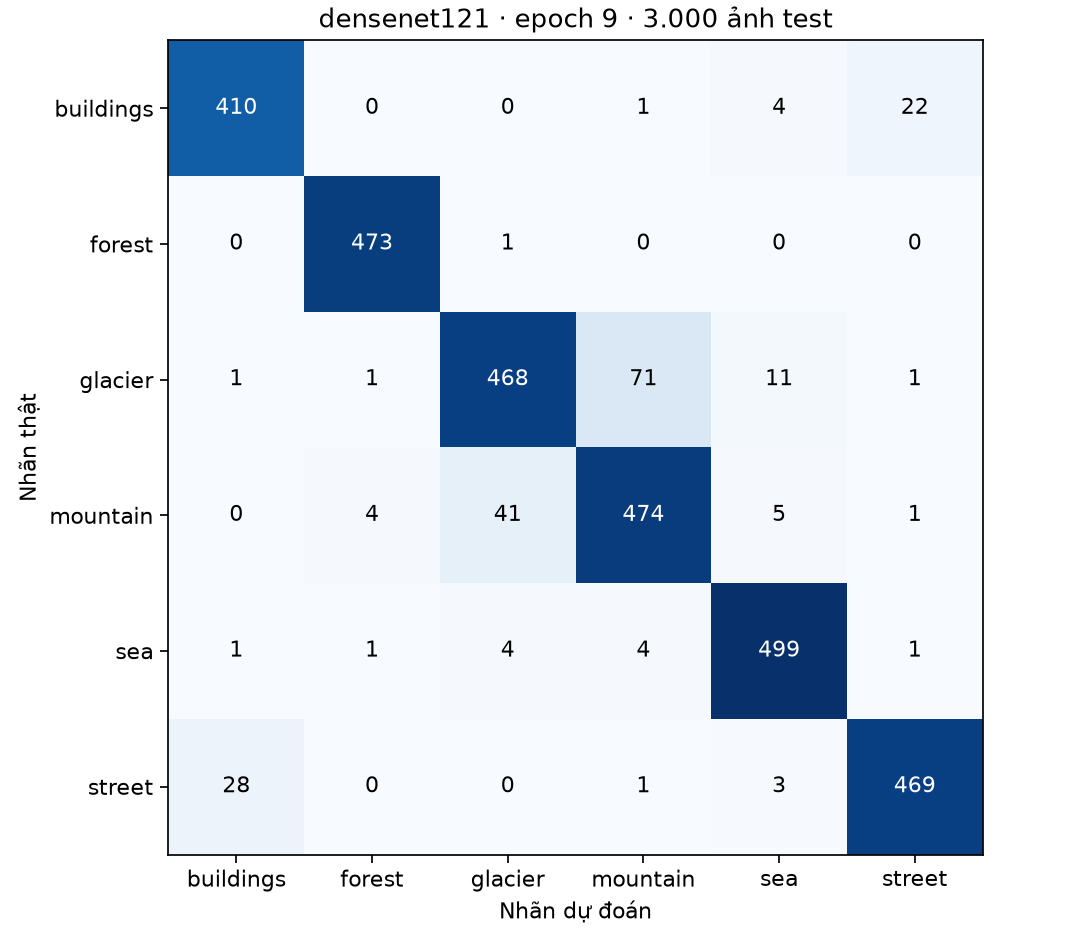

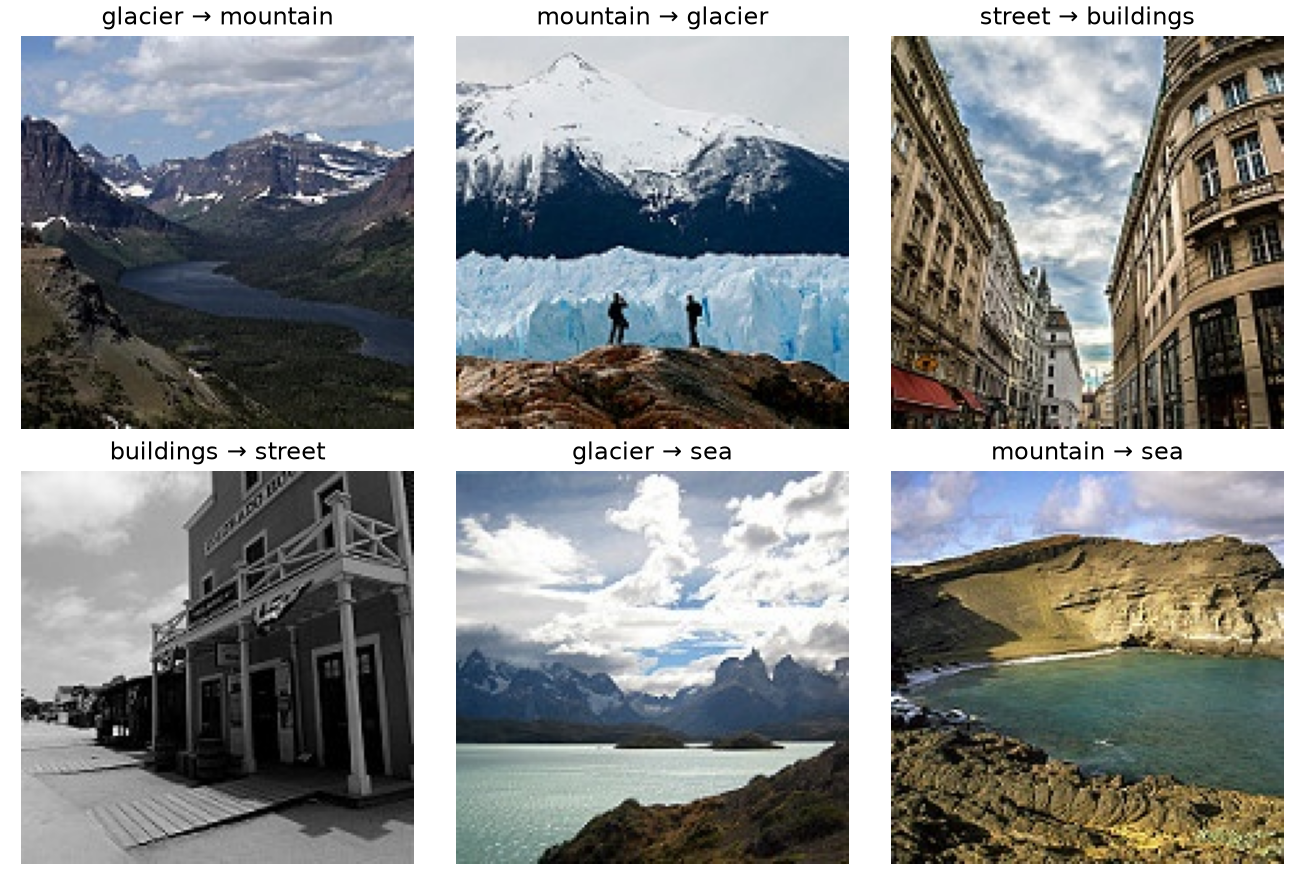

In [9]:
for filename in ('confusion.png','errors.png'):
    display(Image(filename=str(evaluation / filename)))

## 15. MODEL INTERPRETABILITY · Diễn giải mô hình

Ma trận nhầm lẫn cho thấy cặp lớp nào khó phân biệt. Để biết vùng ảnh nào đóng góp vào điểm của một lớp, Grad-CAM cần gradient của điểm lớp theo feature map. Workflow hiện tại chưa sinh Grad-CAM cho checkpoint DenseNet121 epoch 9, nên chưa có bằng chứng về vùng ảnh mà model dựa vào.

## 16. BEST MODEL · Checkpoint cuối và demo

DenseNet121 epoch 9 đạt 93,56% validation accuracy và 93,10% test accuracy. Ô dưới dùng đúng checkpoint đó để dự đoán ảnh mới. Đổi image_path thành đường dẫn tới ảnh của bạn. Điểm softmax mô tả mức ưu tiên giữa sáu lớp. Ảnh ví dụ thuộc seg_pred và chưa có nhãn thật.

10004.jpg → street | softmax 0.8663 | densenet121 | finetune | epoch 9


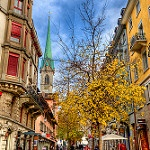

In [10]:
from evaluation.demo import EXAMPLE, predict
from PIL import Image as PILImage
image_path = EXAMPLE
result = predict(image_path)
assert result['checkpoint_sha256'] == m['version']['checkpoint_sha256']
with PILImage.open(image_path) as image:
    display(image.convert('RGB'))
print(f"{image_path.name} → {result['label']} | softmax {result['softmax']:.4f} | {result['run']} | {result['stage']} | epoch {result['epoch']}")